# 05 · Haah's cubic code: fractons in three dimensions

Everything so far was two-dimensional. Haah's cubic code puts **two qubits on every site** of a cubic
lattice and one $X$-type and one $Z$-type term on every cube:

$$\sigma_X=(1+xy+yz+zx,\ \ 1+x+y+z)\quad\text{on }(X_1,X_2),\qquad
  \sigma_Z=(1+\bar x+\bar y+\bar z,\ \ 1+\bar x\bar y+\bar y\bar z+\bar z\bar x)\quad\text{on }(Z_1,Z_2).$$

Read each polynomial as a list of cube corners: $1+x+y+z$ is the origin and its three neighbours,
$xy+yz+zx$ the three face-diagonal corners. The $Z$ cube is the $X$ cube reflected through the cube
centre with the two qubits swapped. The model's degeneracy depends on the arithmetic of $L$, it has no
string-like logical operators, and its excitations are immobile: fractons.

In [1]:
import sys
sys.path.insert(0, "..")

import time
import numpy as np
import matplotlib.pyplot as plt
import gsd
from gsd import Poly, fractals

H = gsd.HAAH_CUBIC
sx, sz = H.generators
print("X cube:", [str(f) for f in sx.x])
print("Z cube:", [str(f) for f in sz.z])
print("terms commute on 2^3 .. 5^3 tori:", all(H.commutes(L) for L in range(2, 6)))

X cube: ['1 + xy + xz + yz', '1 + x + y + z']
Z cube: ['1 + x^-1 + y^-1 + z^-1', '1 + x^-1y^-1 + x^-1z^-1 + y^-1z^-1']
terms commute on 2^3 .. 5^3 tori: True


Commutation is one line of algebra too. An $X$ term and a $Z$ term overlap on
$\sigma_{X,1}\bar\sigma_{Z,1}+\sigma_{X,2}\bar\sigma_{Z,2}$ qubits (at every relative translation), and that
must vanish mod 2:

In [2]:
overlap = (sx.x[0] * sz.z[0].bar() + sx.x[1] * sz.z[1].bar()).mod(2)
print("sigma_X . bar(sigma_Z) =", overlap or 0)

sigma_X . bar(sigma_Z) = 0


## 1. The degeneracy, by brute force

$n=2L^3$ qubits and $2L^3$ terms, so the check matrix is $2L^3\times4L^3$. Gaussian elimination is fine
up to $L\approx8$ (a $1024\times2048$ matrix).

In [3]:
for L in range(2, 9):
    t0 = time.perf_counter()
    k = H.log_gsd(L, method="brute")
    print(f"L={L}:  n = {2 * L ** 3:5d}   log2 GSD = {k:3d}   ({time.perf_counter() - t0:.2f}s)")

L=2:  n =    16   log2 GSD =   6   (0.00s)
L=3:  n =    54   log2 GSD =   2   (0.00s)
L=4:  n =   128   log2 GSD =  14   (0.00s)
L=5:  n =   250   log2 GSD =   2   (0.00s)
L=6:  n =   432   log2 GSD =   6   (0.01s)
L=7:  n =   686   log2 GSD =   2   (0.01s)
L=8:  n =  1024   log2 GSD =  30   (0.03s)


## 2. The degeneracy, by algebra

By $L=32$ brute force would need a $65536\times131072$ matrix. The group ring makes the problem
smaller instead.

**One species per sector.** With one $X$ species, the $X$ block of $F$ is the map $a\mapsto a\,\sigma_X$ from
$R$ to $R^2$, whose kernel is the annihilator of the ideal $I=(1+xy+yz+zx,\ 1+x+y+z)$. Group rings are
Frobenius algebras, so $\dim\operatorname{Ann}(I)=\dim R/I$, and
$\operatorname{rank}F_X=N-\dim R/I$. The $Z$ sector is the mirror image (same dimension), so

$$\log_2\mathrm{GSD}=2N-\operatorname{rank}F_X-\operatorname{rank}F_Z=2\dim_{\mathbb F_2}R/I .$$

**Eliminate $z$.** $1+x+y+z$ is linear in $z$: modulo $I$, $z=1+x+y$. Substituting turns the 3D ring into
a 2D one,

$$R/I\;\cong\;\mathbb F_2[x,y]\,\big/\,\big(x^L-1,\ y^L-1,\ (1+x+y)^L-1,\ g(x,y)\big),\qquad
  g=1+xy+(x+y)(1+x+y),$$

and an $L^3$-site problem becomes an $L^2$-site one. `gsd.quotient_dim` does this automatically.

In [4]:
g = (Poly("1 + xy") + (Poly("x + y") * Poly("1 + x + y"))).mod(2)
print("g(x, y, 1 + x + y) =", g)
for L in range(2, 7):
    assert H.log_gsd(L) == H.log_gsd(L, method="brute")
print("algebra == brute force for L = 2..6")

Ls = list(range(2, 65))
t0 = time.perf_counter()
ks = [H.log_gsd(L) for L in Ls]
print(f"L = 2..64 in {time.perf_counter() - t0:.1f}s")
for L, k in zip(Ls, ks):
    if k > 2:
        print(f"  L={L:2d}  log2 GSD = {k}")

g(x, y, 1 + x + y) = 1 + x + y + x^2 + xy + y^2
algebra == brute force for L = 2..6


L = 2..64 in 11.5s
  L= 2  log2 GSD = 6
  L= 4  log2 GSD = 14
  L= 6  log2 GSD = 6
  L= 8  log2 GSD = 30
  L=10  log2 GSD = 6
  L=12  log2 GSD = 14
  L=14  log2 GSD = 6
  L=15  log2 GSD = 50
  L=16  log2 GSD = 62
  L=18  log2 GSD = 6
  L=20  log2 GSD = 14
  L=22  log2 GSD = 6
  L=24  log2 GSD = 30
  L=26  log2 GSD = 6
  L=28  log2 GSD = 14
  L=30  log2 GSD = 102
  L=32  log2 GSD = 126
  L=34  log2 GSD = 6
  L=36  log2 GSD = 14
  L=38  log2 GSD = 6
  L=40  log2 GSD = 30
  L=42  log2 GSD = 6
  L=44  log2 GSD = 14
  L=45  log2 GSD = 50
  L=46  log2 GSD = 6
  L=48  log2 GSD = 62
  L=50  log2 GSD = 6
  L=52  log2 GSD = 14
  L=54  log2 GSD = 6
  L=56  log2 GSD = 30
  L=58  log2 GSD = 6
  L=60  log2 GSD = 206
  L=62  log2 GSD = 6
  L=63  log2 GSD = 242
  L=64  log2 GSD = 254


Two regularities stand out:

* **$\log_2\mathrm{GSD}=4L-2$ at $L=2^n$**, the largest values, linear in $L$ (sub-extensive, as for the 2D
  fractal stencils);
* **$\log_2\mathrm{GSD}=2$ for most odd $L$**. That is the floor: both generators of $I$ vanish at
  $x=y=z=1$, a point on every torus, so $\dim R/I\ge1$ always.

In between, the arithmetic of $L$ decides: the same UV/IR mixing as Newman–Moore, now in 3D.

Text(0.5, 1.0, "Haah's cubic code on $L\\times L\\times L$ tori")

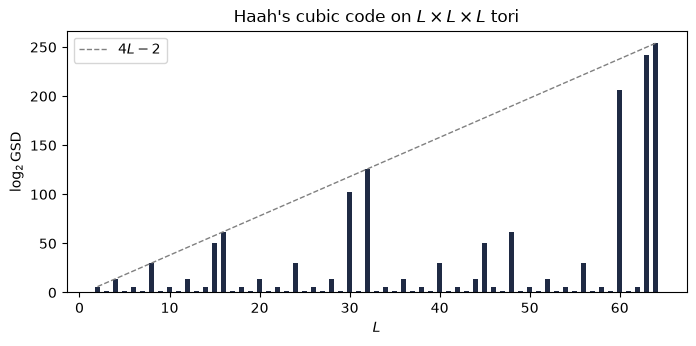

In [5]:
assert all(H.log_gsd(2 ** a) == 4 * 2 ** a - 2 for a in range(1, 7))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(Ls, ks, color="#1f2a44", width=0.6)
ax.plot(Ls, [4 * L - 2 for L in Ls], "--", color="0.5", lw=1, label="$4L-2$")
ax.set_xlabel("$L$"), ax.set_ylabel("$\\log_2\\mathrm{GSD}$"), ax.legend()
ax.set_title("Haah's cubic code on $L\\times L\\times L$ tori")

## 3. No strings: the fractal operators

In the toric code a string of $Z$s creates two excitations at its ends, and the string can be extended
to move them. Here every term is a cube, and no string commutes with the cubes along its length.

What does work is a fractal. Put $Z$ on the second qubit in the pattern $b$. The $X$ cubes it
anticommutes with are given by $\bar\sigma_{X,2}\,b$, and with $\bar\sigma_{X,2}=1+\bar x+\bar y+\bar z$ and
$b=\bar\sigma_{X,2}^{\,2^n-1}$, Frobenius gives

$$\bar\sigma_{X,2}\,b=\bar\sigma_{X,2}^{\,2^n}=1+\bar x^{2^n}+\bar y^{2^n}+\bar z^{2^n}:$$

$4^n$ $Z$ operators on a Sierpiński tetrahedron, and exactly **four** excitations at its corners. None of
them can be moved alone: each is a fracton.

In [6]:
sbar = sx.x[1].bar()
for n in range(1, 6):
    b, corners = fractals.power_pattern(sbar, n)
    print(f"n={n}: {len(b):5d} = 4^{n} Z's, excitations at {sorted(corners.terms)}")

n=1:     4 = 4^1 Z's, excitations at [(-2, 0, 0), (0, -2, 0), (0, 0, -2), (0, 0, 0)]
n=2:    16 = 4^2 Z's, excitations at [(-4, 0, 0), (0, -4, 0), (0, 0, -4), (0, 0, 0)]
n=3:    64 = 4^3 Z's, excitations at [(-8, 0, 0), (0, -8, 0), (0, 0, -8), (0, 0, 0)]
n=4:   256 = 4^4 Z's, excitations at [(-16, 0, 0), (0, -16, 0), (0, 0, -16), (0, 0, 0)]
n=5:  1024 = 4^5 Z's, excitations at [(-32, 0, 0), (0, -32, 0), (0, 0, -32), (0, 0, 0)]


The same check on an actual torus, through the check matrix rather than the polynomials: put the
pattern on a $40^3$ torus (big enough that the fractal does not overlap itself; $-32\equiv8$) and count
the violated $X$ cubes.

1024 Z's on the 40^3 torus violate 4 X cubes, at [(0, 0, 0), (0, 0, 8), (0, 8, 0), (8, 0, 0)]


Text(0.5, 0.92, "1024 Z's, 4 fractons")

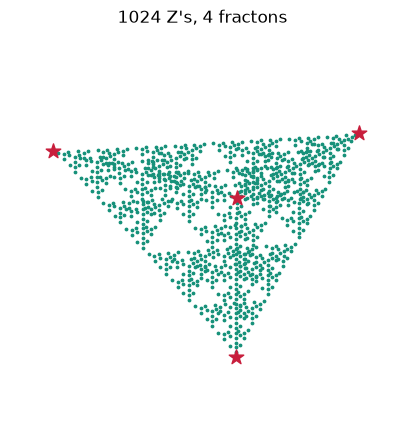

In [7]:
L, n = 40, 5
b, _ = fractals.power_pattern(sbar, n)
pattern = b.on((L, L, L))
violated = gsd.ring_mul(sbar.on((L, L, L)), pattern)
print(f"{int(pattern.sum())} Z's on the {L}^3 torus violate {int(violated.sum())} X cubes,",
      "at", [tuple(map(int, p)) for p in np.argwhere(violated)])

pts, c = np.array(list(b.terms)), np.array(list(fractals.power_pattern(sbar, n)[1].terms))
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*pts.T, s=3, color="#17917a", depthshade=False)
ax.scatter(*c.T, s=120, marker="*", color="#c81e3c", depthshade=False)
ax.view_init(22, 35), ax.set_axis_off()
ax.set_title(f"{len(b)} Z's, 4 fractons")

On a $2^n\times2^n\times2^n$ torus, $\bar x^{2^n}=1$, so all four corners land on the same cube and cancel
($4\equiv0$): the open fractal closes into an operator that commutes with every term. Closed fractals
like this are what the extra degeneracy at $L=2^n$ is made of — the 3D analogue of Newman–Moore closing
at $L=2^n-1$.

In [8]:
for L in (16, 32):
    b, _ = fractals.power_pattern(sbar, L.bit_length() - 1)
    v = gsd.ring_mul(sbar.on((L, L, L)), b.on((L, L, L)))
    print(f"L={L}: the {len(b)}-Z fractal violates {int(v.sum())} cubes -> it commutes with every term")

L=16: the 256-Z fractal violates 0 cubes -> it commutes with every term
L=32: the 1024-Z fractal violates 0 cubes -> it commutes with every term
